# Flux: NEE of the LI-7200 in the hot summer 2026 (June-September)

# About this notebook

The summer of 2026 was the hottest of the LI-7200 record at CH-LAE. This notebook asks whether the
heat reduced the net CO2 uptake of the forest from June to September, and whether a reduction came
from lower gross uptake (`GPP`) or from higher ecosystem respiration (`RECO`). The reference is the
LI-7200 (`IRGA72`) record of the same months in 2016-2025. The notebook computes no product and
changes nothing in the flux chain.

**Sign convention and units.** `NEE` is negative when the forest takes up CO2. Half-hourly values
are in µmol CO2 m⁻² s⁻¹; sums are in gC m⁻² (1 µmol m⁻² s⁻¹ over 30 minutes is 0.0216 gC m⁻²).

**Inputs**

- `30_FLUX_POST-PROCESSING_CHAIN/IRGA72/05_FPPC_IRGA72_NEE_2016-2026.09`: `NEE` gap-filled with
  XGBoost for the three USTAR scenarios (`CUT_16`, `CUT_50`, `CUT_84`), the measured `NEE`
  (`CUT_50`, flags 0 and 1), `GPP` and `RECO` of the nighttime (`NT`) and daytime (`DT`)
  partitioning, the `DAYTIME` flag, and the measured air temperature and radiation.
- `30_FLUX_POST-PROCESSING_CHAIN/IRGA72/25_..._LE_...` and `35_..._H_...`: latent and sensible heat
  flux and evapotranspiration, as indicators of the water status of the canopy.
- `10_METEO/30_PRODUCTS/99_METEO_MERGED_2004-2026.09`: air temperature (`TA`), vapour pressure
  deficit (`VPD`), incoming shortwave radiation (`SW_IN`), precipitation (`PREC`) and soil water
  content (`SWC`).
- `10_METEO/10_REFERENCE/MeteoSwiss_LAE_30MIN_2004-2026.09`: air temperature of the MeteoSwiss
  station Lägern (LAE), as a check of the tower temperature that does not depend on its probes.

**Two limitations of the 2026 data.** Precipitation and soil water content in the meteo products end
on 31 December 2025 and are not yet available for 2026. The water status of 2026 is therefore
described by the evaporative fraction and the evapotranspiration measured by the eddy-covariance
system, not by rain and soil moisture. The temperature and humidity probe at 47 m was replaced in
June 2026; the homogenised `TA` and `VPD` put the new probe on the level of the earlier one, and the
MeteoSwiss station serves as an independent check.

# Main findings

- **Net uptake.** From June to September 2026 the forest took up 228 gC m⁻² (`NEE`, `CUT_50`),
  against 361 on average in 2016-2025 (240 in 2022 to 513 in 2019): 133 gC m⁻² or 37 % less, 1.7
  standard deviations below the mean. 2026 has the weakest uptake of the eleven years in all three
  USTAR scenarios (`CUT_16` 258, `CUT_84` 201 gC m⁻²), but it lies only 12 gC m⁻² below 2022. The
  random uncertainty of the sum is 6 gC m⁻².
- **Timing.** June and July were close to the mean (-125 and -104 against -134 and -114 gC m⁻²).
  The forest was about carbon-neutral in August (-3 against -66) and September (+5 against -46);
  these two months carry 115 of the 133 gC m⁻² of the anomaly.
- **Weather.** June to September 2026 was the hottest season of the record: `TA` 20.8 °C against
  18.0 °C (16.9 to 19.1), confirmed by the MeteoSwiss station Lägern (+2.9 K); 270 hours above
  28 °C (11 to 106 in the other years), 24 days with a maximum of at least 30 °C (0 to 8), mean
  `VPD` 1.14 kPa (0.46 to 0.79) and the highest `SW_IN`. Heat spells fell in the second half of
  June and from late July to mid-August. Precipitation and soil water content are not yet
  available for 2026.
- **Water status.** The midday evaporative fraction was the lowest of the record (0.42 against
  0.47 to 0.62) and fell from 0.54 in June to 0.28 in September, also after temperature and `VPD`
  had returned to the usual range. Evapotranspiration was the lowest of the record (353 mm against
  357 to 422 mm).
- **Uptake under heat.** In every year, uptake at high light (`SW_IN` ≥ 600 W m⁻²) decreases with
  air temperature, from -23.4 µmol m⁻² s⁻¹ below 20 °C to -9.4 above 28 °C in 2016-2025. In 2026
  it was 2.8 to 4.2 µmol m⁻² s⁻¹ lower than in the reference years in every temperature class,
  including below 20 °C, and 0.8 to 4.0 lower in every `VPD` class.
- **Conditions against a lasting reduction.** At the same month, light and temperature, the
  reference years give the 2026 daytime half-hours about the same `NEE` as their own mean (effect
  of the conditions +0.1 µmol m⁻² s⁻¹; +0.3 with `VPD` instead of `TA`). The measured 2026 uptake was
  2.8 µmol m⁻² s⁻¹ lower than this expectation (1.7 with `VPD`): close to zero in June and July
  (-0.4 and +1.5), +5.1 in August and +6.4 in September. The more frequent hot half-hours explain
  little of the deficit; most of it is a reduction in August and September that the half-hourly
  conditions do not account for.
- **GPP and RECO.** `GPP` was the lowest of the record with both partitioning methods (nighttime
  933 against 1025 to 1341 gC m⁻², -280; daytime 981 against 1033 to 1457, -314). Nighttime `RECO`
  was 147 gC m⁻² below the mean (705, second lowest), and measured night-time `NEE` in July and
  August was 1.4 and 1.9 µmol m⁻² s⁻¹ below that of the reference years at the same temperature.
  Lower `GPP` caused the reduction; lower respiration offset about half of it. The largest weekly
  deficits of `GPP` fell in the weeks from 3 to 23 August (up to 6.8 gC m⁻² d⁻¹ with the nighttime
  method in the week from 10 August), a shorter one in the week from 22 June.

</br>

# Settings

In [1]:
from pathlib import Path

DATADIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow")
FILE_NEE72 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA72\05_FPPC_IRGA72_NEE_2016-2026.09.parquet"
FILE_LE72 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA72\25_FPPC_IRGA72_LE_2016-2026.09.parquet"
FILE_H72 = r"30_FLUX_POST-PROCESSING_CHAIN\IRGA72\35_FPPC_IRGA72_H_2016-2026.09.parquet"
FILE_METEO = r"10_METEO\30_PRODUCTS\99_METEO_MERGED_2004-2026.09.parquet"
FILE_LAE = r"10_METEO\10_REFERENCE\MeteoSwiss_LAE_30MIN_2004-2026.09.parquet"

# The season compared, the year in question and its reference years.
MONTHS = [6, 7, 8, 9]
SEASON = 'Jun-Sep'
YEAR = 2026
REF_YEARS = list(range(2016, 2026))

# Gap-filled NEE of the three USTAR scenarios; CUT_50 is the main series.
NEE_GF = {'CUT_16': 'NEE_L3.1_L3.3_CUT_16_QCF_gfXG',
          'CUT_50': 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG',
          'CUT_84': 'NEE_L3.1_L3.3_CUT_84_QCF_gfXG'}
NEE_FLAG = 'FLAG_NEE_L3.1_L3.3_CUT_50_QCF_gfXG_ISFILLED'  # 0 measured, 1 gap-filled
NEE_MEAS = 'NEE_L3.1_L3.3_CUT_50_QCF'                      # the measured records only
NEE_RANDUNC = 'NEE_L3.1_L3.3_CUT_50_QCF_gfXG_RANDUNC'
PART = {'GPP_NT': 'GPP_NT_OF_CUT_50', 'RECO_NT': 'RECO_NT_OF_CUT_50',
        'GPP_DT': 'GPP_DT_OF_CUT_50', 'RECO_DT': 'RECO_DT_OF_CUT_50'}
DAYTIME = 'DAYTIME'
TA_MEAS = 'TA_T1_47_1_HOMOGENIZED_MEASURED'  # measured TA, homogenised across the probe changes
SW_MEAS = 'SW_IN_T1_47_1_MEASURED'

LE_GF, LE_FLAG = 'LE_L3.1_L3.3_CUT_NONE_QCF_gfXG', 'FLAG_LE_L3.1_L3.3_CUT_NONE_QCF_gfXG_ISFILLED'
ET_GF = 'ET_L3.1_L3.3_CUT_NONE_QCF_gfXG'      # mm per half-hour
H_GF, H_FLAG = 'H_L3.1_L3.3_CUT_NONE_QCF_gfXG', 'FLAG_H_L3.1_L3.3_CUT_NONE_QCF_gfXG_ISFILLED'

METEO_COLS = {'TA_T1_47_1_HOMOGENIZED_gfXG': 'TA', 'VPD_T1_47_1_HOMOGENIZED': 'VPD',
              'FLAG_VPD_T1_47_1_ISFILLED': 'VPD_FLAG', 'SW_IN_T1_47_1_gfXG': 'SW_IN',
              'PREC_TOT_T1_47_1_HOMOGENIZED': 'PREC', 'SWC_FF1_0.1_1_HOMOGENIZED': 'SWC_0.1',
              'SWC_FF1_0.2_1_HOMOGENIZED': 'SWC_0.2'}
LAE_TA = 'TA_LAE_MS'

# Thresholds of hot and dry conditions.
TA_HOT = 28.0        # °C, half-hours above this count as hot
TA_HOT_DAY = 30.0    # °C, days with a maximum at or above this count as hot days
VPD_HIGH = 2.0       # kPa

# Classes of the light-response analysis (measured daytime half-hours).
SW_MIN = 20                                        # W m-2, lower limit of a daytime half-hour
SW_BINS = [20, 100, 200, 300, 400, 500, 600, 700, 800, 1200]
SW_HIGH = 600                                      # W m-2, "high light"
TA_BINS, TA_LABELS = [-50, 20, 24, 28, 50], ['< 20 °C', '20-24 °C', '24-28 °C', '≥ 28 °C']
VPD_BINS, VPD_LABELS = [0, 0.5, 1.0, 1.5, 2.0, 10], ['< 0.5', '0.5-1.0', '1.0-1.5', '1.5-2.0', '≥ 2.0']
MIN_N = 10   # fewest half-hours a bin must hold to be shown or used as reference

# Midday window for the evaporative fraction LE / (LE + H), CET.
MIDDAY = (11, 15)

GC = 12.011e-6 * 1800  # umol m-2 s-1 over one half-hour -> gC m-2
C_YEAR, C_REF = '#b2182b', '0.55'

# Imports

In [2]:
import calendar
import importlib.metadata
import textwrap
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=RuntimeWarning)
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START:%Y-%m-%d %H:%M:%S}")
for _p in ('pandas', 'numpy', 'matplotlib'):
    print(f"{_p} version: v{importlib.metadata.version(_p)}")

Last run: 2026-11-19 17:07:45
pandas version: v3.0.3
numpy version: v2.4.6
matplotlib version: v3.10.9


# Helpers

In [3]:
def tabcap(text, width=100):
    """Print a table caption. Called by `styled`, so no table can be shown without one."""
    print(textwrap.fill(f"Table — {text}", width) + "\n")


def figcap(fig, text, width=125):
    """Place a caption under a figure drawn with a layout engine. Call after the last axes."""
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    fig.supxlabel(textwrap.fill(f"Figure — {text}", width), fontsize=9, ha='left', x=0.005)


def styled(data, caption, fmt="{:.2f}", subset=None, cmap="RdBu_r", axis=None, center=True):
    """`data` as a table with a caption, fixed decimals and a colour scale over its values."""
    numeric = [c for c in data.columns if pd.api.types.is_numeric_dtype(data[c])]
    fmt = {c: fmt for c in numeric} if isinstance(fmt, str) else {
        c: fmt.get(c, "{:.2f}") for c in numeric}
    tabcap(caption)
    styler = data.style.format(fmt, na_rep="-")
    if cmap is None or not numeric:
        return styler
    values = data.loc[subset] if isinstance(subset, tuple) else (
        data[subset] if subset is not None else data[numeric])
    limits = {}
    if center:
        absmax = np.nanmax(np.abs(values.to_numpy(dtype=float)))
        limits = dict(vmin=-absmax, vmax=absmax)
    return styler.background_gradient(cmap=cmap, subset=subset, axis=axis,
                                      text_color_threshold=0.4, **limits)


def season(frame):
    """The rows of `frame` in the months of MONTHS."""
    return frame[frame.index.month.isin(MONTHS)]


def per_year(s, how='sum'):
    """Aggregate `s` to one value per year."""
    return s.groupby(s.index.year).agg(how)


def against_reference(table, low_is_bad=True):
    """Add the reference statistics (mean, SD, min, max) and the anomaly of YEAR to a year table.

    `table` has one row per year. Returns a table with one row per column of `table`: the value of
    YEAR, the mean, SD, minimum and maximum of REF_YEARS, the anomaly of YEAR against the mean in
    absolute terms and in SDs, and the rank of YEAR among all years (1 = lowest value).
    """
    ref = table.loc[REF_YEARS]
    out = pd.DataFrame({str(YEAR): table.loc[YEAR], 'ref mean': ref.mean(), 'ref SD': ref.std(),
                        'ref min': ref.min(), 'ref max': ref.max()})
    out['anomaly'] = out[str(YEAR)] - out['ref mean']
    out['anomaly (SD)'] = out['anomaly'] / out['ref SD']
    out['rank of 1 lowest'] = table.loc[REF_YEARS + [YEAR]].rank().loc[YEAR]
    out['years'] = f"of {len(REF_YEARS) + 1}"
    return out


def binned_mean(frame, value, rows, cols):
    """Mean and count of `value` per class of `rows` (index) and `cols` (columns)."""
    g = frame.groupby([rows, cols], observed=True)[value]
    return g.mean().unstack(), g.size().unstack()


def week_of_season(index):
    """Week number counted from 1 June of each year. The last 10 days form one block."""
    start = pd.to_datetime([f"{y}-{MONTHS[0]:02d}-01" for y in index.year])
    return np.minimum((index.normalize() - start).days // 7, 16)

</br>

# Load data

In [4]:
_files = {'IRGA72 NEE (05)': DATADIR / FILE_NEE72, 'IRGA72 LE (25)': DATADIR / FILE_LE72,
          'IRGA72 H (35)': DATADIR / FILE_H72, 'meteo, merged (99)': DATADIR / FILE_METEO,
          'MeteoSwiss LAE': DATADIR / FILE_LAE}
_missing = [f"{k}: {p}" for k, p in _files.items() if not p.exists()]
if _missing:
    raise FileNotFoundError("This notebook reads the flux and meteo products from the external data "
                            "folder, which is not available here. Missing:\n  " + "\n  ".join(_missing))

_nee_cols = [*NEE_GF.values(), NEE_FLAG, NEE_MEAS, NEE_RANDUNC, *PART.values(), DAYTIME, TA_MEAS, SW_MEAS]
n72 = pd.read_parquet(_files['IRGA72 NEE (05)'], columns=_nee_cols)
le72 = pd.read_parquet(_files['IRGA72 LE (25)'], columns=[LE_GF, LE_FLAG, ET_GF])
h72 = pd.read_parquet(_files['IRGA72 H (35)'], columns=[H_GF, H_FLAG])
met = pd.read_parquet(_files['meteo, merged (99)'], columns=list(METEO_COLS)).rename(columns=METEO_COLS)
lae = pd.read_parquet(_files['MeteoSwiss LAE'], columns=[LAE_TA])
# The MeteoSwiss record is indexed by the end of the half-hour; move it to the middle.
lae.index = lae.index - pd.Timedelta('15min')

df = n72.join(le72).join(h72).join(met).join(lae)
df['year'] = df.index.year
df['month'] = df.index.month
s = season(df).copy()
print(f"{len(df):,} half-hours from {df.index[0]} to {df.index[-1]}; {len(s):,} in {SEASON}")

188,448 half-hours from 2016-01-01 00:15:00 to 2026-09-30 23:45:00; 64,416 in Jun-Sep


## 📋 Table: input files and the run they come from

In [5]:
_inputs = pd.DataFrame({
    'file': [p.name for p in _files.values()],
    'modified': [f"{datetime.fromtimestamp(p.stat().st_mtime):%Y-%m-%d %H:%M}" for p in _files.values()],
}, index=list(_files))
display(styled(_inputs, caption="the input files with their modification time. The numbers in this notebook "
                                "belong to the runs of these dates", cmap=None))

Table — the input files with their modification time. The numbers in this notebook belong to the
runs of these dates



,file,modified
IRGA72 NEE (05),05_FPPC_IRGA72_NEE_2016-2026.09.parquet,2026-11-04 15:46
IRGA72 LE (25),25_FPPC_IRGA72_LE_2016-2026.09.parquet,2026-11-04 16:50
IRGA72 H (35),35_FPPC_IRGA72_H_2016-2026.09.parquet,2026-11-01 15:07
"meteo, merged (99)",99_METEO_MERGED_2004-2026.09.parquet,2026-10-29 21:02
MeteoSwiss LAE,MeteoSwiss_LAE_30MIN_2004-2026.09.parquet,2026-10-23 12:20


## Integrity checks

In [6]:
_issues = []
for _name, _df in (('NEE 05', n72), ('LE 25', le72), ('H 35', h72), ('meteo', met)):
    if _df.index.duplicated().any():
        _issues.append(f"{_name}: duplicate timestamps")
if not (df.index.to_series().diff().dropna() == pd.Timedelta('30min')).all():
    _issues.append("the joined frame has index gaps")
if df.index[-1] != pd.Timestamp(f"{YEAR}-09-30 23:45"):
    _issues.append(f"the record ends on {df.index[-1]}, not on 30 September {YEAR}")
for _c in [*NEE_GF.values(), *PART.values(), LE_GF, H_GF, ET_GF, 'TA', 'VPD', 'SW_IN']:
    if s[_c].isna().any():
        _issues.append(f"{_c}: {int(s[_c].isna().sum())} missing values in {SEASON}")
_n = s.groupby('year').size()
_short = {y: int(n) for y, n in _n.items() if n != 122 * 48}
if _short:
    _issues.append(f"incomplete seasons: {_short}")
if not (s[NEE_MEAS].notna() == s[NEE_FLAG].eq(0)).all():
    _issues.append("the fill flag and the measured NEE disagree")
if s.loc[s['year'] == YEAR, ['PREC', 'SWC_0.1', 'SWC_0.2']].notna().any().any():
    _issues.append(f"PREC or SWC now reach into {YEAR}; extend the drought section to use them")
assert not _issues, "the inputs are not what this notebook assumes: " + "; ".join(_issues)
print(f"Integrity checks passed: {len(_n)} complete {SEASON} seasons, gap-filled series complete. "
      f"PREC and SWC are not available for {YEAR}.")

Integrity checks passed: 11 complete Jun-Sep seasons, gap-filled series complete. PREC and SWC are not available for 2026.


</br>

# 1. Carbon fluxes from June to September

Sums of the gap-filled `NEE` and of `GPP` and `RECO` from both partitioning methods over
1 June to 30 September. The USTAR scenarios `CUT_16` and `CUT_84` give the uncertainty from the
USTAR threshold; the random uncertainty of the sum is the root of the summed squared half-hourly
random uncertainties.

In [7]:
_cols = {f'NEE {k}': v for k, v in NEE_GF.items()} | PART
sums = (s[list(_cols.values())] * GC).groupby(s['year']).sum().rename(columns={v: k for k, v in _cols.items()})
sums['NEE random unc.'] = np.sqrt((s[NEE_RANDUNC] ** 2).groupby(s['year']).sum()) * GC
sums['measured (%)'] = s[NEE_FLAG].eq(0).groupby(s['year']).mean() * 100
sums.index.name = 'year'

## 📋 Table: June-September sums per year

In [8]:
_t = pd.concat([sums, sums.loc[REF_YEARS].agg(['mean', 'min', 'max']).rename(
    index=lambda i: f"2016-2025 {i}")])
display(styled(_t, caption=f"sums of NEE (three USTAR scenarios), GPP and RECO (nighttime NT and daytime DT "
                           f"partitioning, CUT_50) from 1 June to 30 September, in gC m⁻², the random "
                           f"uncertainty of the NEE sum (CUT_50) and the share of measured NEE half-hours",
               fmt={**{c: "{:.0f}" for c in sums.columns}, 'measured (%)': "{:.0f}"},
               subset=(_t.index[:len(sums)], ['NEE CUT_16', 'NEE CUT_50', 'NEE CUT_84']),
               cmap='RdYlGn_r', center=False))

Table — sums of NEE (three USTAR scenarios), GPP and RECO (nighttime NT and daytime DT partitioning,
CUT_50) from 1 June to 30 September, in gC m⁻², the random uncertainty of the NEE sum (CUT_50) and
the share of measured NEE half-hours



,NEE CUT_16,NEE CUT_50,NEE CUT_84,GPP_NT,RECO_NT,GPP_DT,RECO_DT,NEE random unc.,measured (%)
2016,-398,-341,-334,1341,1000,1286,1035,9,26
2017,-313,-278,-265,1238,960,1457,1409,8,28
2018,-364,-339,-331,1142,802,1033,822,7,27
2019,-529,-513,-504,1324,811,1334,875,8,29
2020,-401,-388,-388,1091,703,1304,1064,7,26
2021,-373,-364,-330,1334,970,1361,1078,9,25
2022,-288,-240,-221,1025,785,1186,978,7,35
2023,-365,-313,-287,1080,767,1227,1002,8,29
2024,-406,-386,-350,1277,891,1326,1231,8,26
2025,-481,-444,-424,1277,833,1439,1091,9,28


## 📋 Table: 2026 against the reference years

In [9]:
_t = against_reference(sums[['NEE CUT_16', 'NEE CUT_50', 'NEE CUT_84', 'GPP_NT', 'RECO_NT', 'GPP_DT', 'RECO_DT']])
_t = _t.rename(columns={'rank of 1 lowest': 'rank (1 = lowest)'})
# For NEE the rank is more useful the other way round: 1 = weakest uptake (highest NEE).
display(styled(_t, caption=f"{SEASON} sums of {YEAR} against the ten reference years {REF_YEARS[0]}-"
                           f"{REF_YEARS[-1]}, in gC m⁻²: the reference mean, standard deviation, minimum and "
                           f"maximum, the anomaly of {YEAR} and its rank among all eleven years (1 = lowest "
                           f"value; for NEE, rank 11 is the weakest uptake)",
               fmt={**{c: "{:.0f}" for c in _t.columns[:6]}, 'anomaly (SD)': "{:+.1f}", 'rank (1 = lowest)': "{:.0f}"},
               subset=['anomaly (SD)'], cmap='RdBu_r'))

Table — Jun-Sep sums of 2026 against the ten reference years 2016-2025, in gC m⁻²: the reference
mean, standard deviation, minimum and maximum, the anomaly of 2026 and its rank among all eleven
years (1 = lowest value; for NEE, rank 11 is the weakest uptake)



,2026,ref mean,ref SD,ref min,ref max,anomaly,anomaly (SD),rank (1 = lowest),years
NEE CUT_16,-258,-392,71,-529,-288,134,+1.9,11,of 11
NEE CUT_50,-228,-361,79,-513,-240,133,+1.7,11,of 11
NEE CUT_84,-201,-343,81,-504,-221,142,+1.8,11,of 11
GPP_NT,933,1213,118,1025,1341,-280,-2.4,1,of 11
RECO_NT,705,852,99,703,1000,-147,-1.5,2,of 11
GPP_DT,981,1295,124,1033,1457,-314,-2.5,1,of 11
RECO_DT,747,1058,168,822,1409,-312,-1.9,1,of 11


## 📊 Plot: cumulative NEE, GPP and RECO from June to September

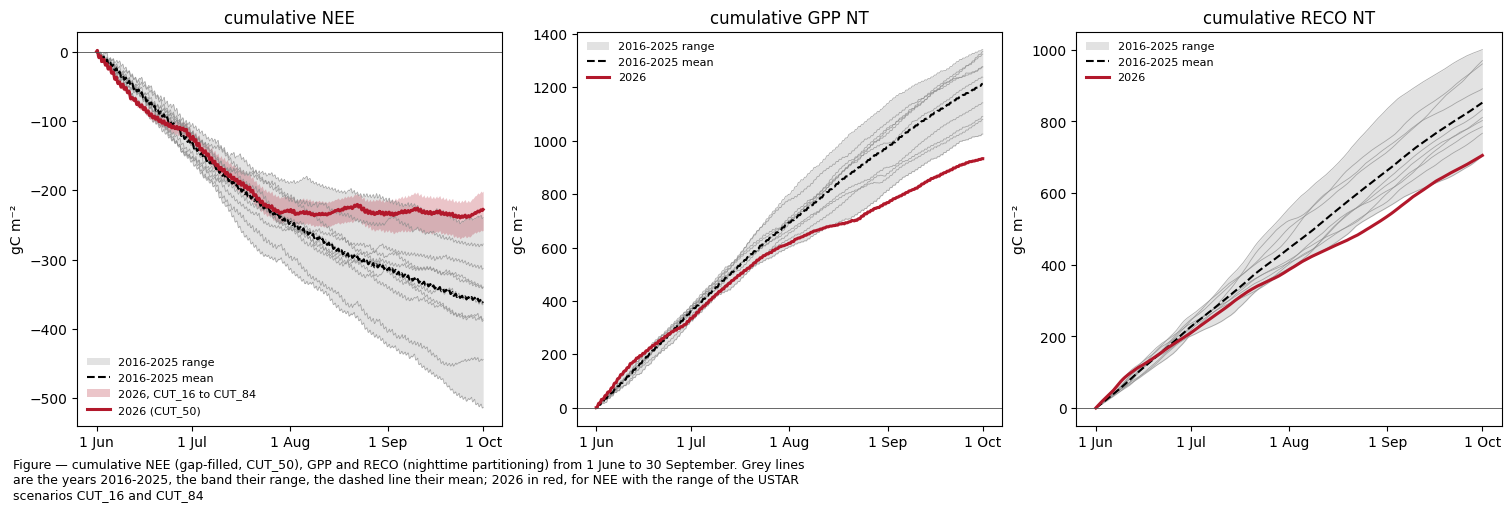

In [10]:
_cum = {k: (s[v] * GC).groupby(s['year']).cumsum() for k, v in
        {'NEE': NEE_GF['CUT_50'], 'GPP_NT': PART['GPP_NT'], 'RECO_NT': PART['RECO_NT']}.items()}
_doy = (s.index - pd.DatetimeIndex(pd.to_datetime(s['year'].astype(str) + '-06-01'))).total_seconds() / 86400

fig, axes = plt.subplots(1, 3, figsize=(15, 5), layout='constrained')
for ax, (name, c) in zip(axes, _cum.items()):
    wide = pd.DataFrame({y: c[s['year'] == y].to_numpy() for y in REF_YEARS + [YEAR]})
    x = _doy[s['year'] == YEAR].to_numpy()
    ref = wide[REF_YEARS]
    ax.fill_between(x, ref.min(axis=1), ref.max(axis=1), color=C_REF, alpha=0.25, lw=0,
                    label=f'{REF_YEARS[0]}-{REF_YEARS[-1]} range')
    for y in REF_YEARS:
        ax.plot(x, ref[y], color=C_REF, lw=0.6, alpha=0.7)
    ax.plot(x, ref.mean(axis=1), color='k', lw=1.5, ls='--', label=f'{REF_YEARS[0]}-{REF_YEARS[-1]} mean')
    if name == 'NEE':
        lo = (s.loc[s['year'] == YEAR, NEE_GF['CUT_16']] * GC).cumsum().to_numpy()
        hi = (s.loc[s['year'] == YEAR, NEE_GF['CUT_84']] * GC).cumsum().to_numpy()
        ax.fill_between(x, lo, hi, color=C_YEAR, alpha=0.25, lw=0, label=f'{YEAR}, CUT_16 to CUT_84')
    ax.plot(x, wide[YEAR], color=C_YEAR, lw=2.2, label=f'{YEAR}' + (' (CUT_50)' if name == 'NEE' else ''))
    ax.axhline(0, color='0.3', lw=0.6)
    ax.set_xticks([0, 30, 61, 92, 122], ['1 Jun', '1 Jul', '1 Aug', '1 Sep', '1 Oct'])
    ax.set_title(f"cumulative {name.replace('_', ' ')}")
    ax.set_ylabel('gC m⁻²')
    ax.legend(frameon=False, fontsize=8, loc='lower left' if name == 'NEE' else 'upper left')
figcap(fig, f"cumulative NEE (gap-filled, CUT_50), GPP and RECO (nighttime partitioning) from 1 June to "
            f"30 September. Grey lines are the years {REF_YEARS[0]}-{REF_YEARS[-1]}, the band their range, "
            f"the dashed line their mean; {YEAR} in red, for NEE with the range of the USTAR scenarios "
            f"CUT_16 and CUT_84")
plt.show()

## 📊 Plot: June-September sums per year

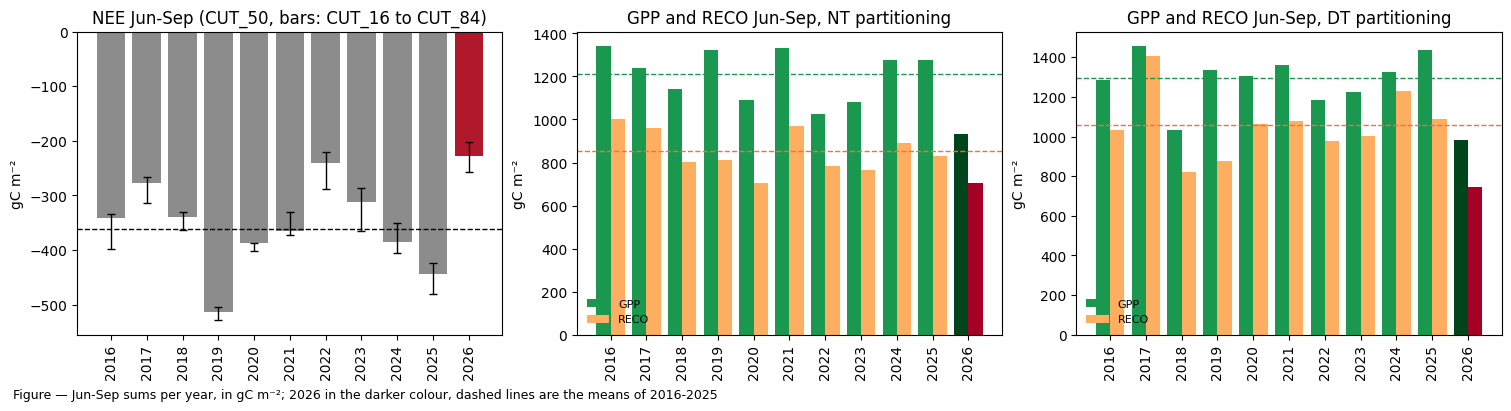

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
_yrs = REF_YEARS + [YEAR]
_col = [C_YEAR if y == YEAR else C_REF for y in _yrs]
ax = axes[0]
ax.bar(_yrs, sums.loc[_yrs, 'NEE CUT_50'], color=_col)
ax.errorbar(_yrs, sums.loc[_yrs, 'NEE CUT_50'],
            yerr=[sums.loc[_yrs, 'NEE CUT_50'] - sums.loc[_yrs, ['NEE CUT_16', 'NEE CUT_84']].min(axis=1),
                  sums.loc[_yrs, ['NEE CUT_16', 'NEE CUT_84']].max(axis=1) - sums.loc[_yrs, 'NEE CUT_50']],
            fmt='none', ecolor='k', capsize=3, lw=1)
ax.axhline(sums.loc[REF_YEARS, 'NEE CUT_50'].mean(), color='k', ls='--', lw=1)
ax.set_title(f'NEE {SEASON} (CUT_50, bars: CUT_16 to CUT_84)')
for ax, (g, r) in zip(axes[1:], [('GPP_NT', 'RECO_NT'), ('GPP_DT', 'RECO_DT')]):
    w = 0.4
    ax.bar(np.array(_yrs) - w / 2, sums.loc[_yrs, g], w, color=['#1a9850' if y != YEAR else '#00441b' for y in _yrs], label='GPP')
    ax.bar(np.array(_yrs) + w / 2, sums.loc[_yrs, r], w, color=['#fdae61' if y != YEAR else '#a50026' for y in _yrs], label='RECO')
    ax.axhline(sums.loc[REF_YEARS, g].mean(), color='#1a9850', ls='--', lw=1)
    ax.axhline(sums.loc[REF_YEARS, r].mean(), color='#f46d43', ls='--', lw=1)
    ax.set_title(f"GPP and RECO {SEASON}, {g.split('_')[1]} partitioning")
    ax.legend(frameon=False, fontsize=8, loc='lower left')
for ax in axes:
    ax.set_ylabel('gC m⁻²')
    ax.set_xticks(_yrs, [str(y) for y in _yrs], rotation=90)
figcap(fig, f"{SEASON} sums per year, in gC m⁻²; {YEAR} in the darker colour, dashed lines are the means of "
            f"{REF_YEARS[0]}-{REF_YEARS[-1]}")
plt.show()

</br>

# 2. How hot and dry 2026 was

Air temperature (`TA`, homogenised), vapour pressure deficit (`VPD`, homogenised) and incoming
shortwave radiation (`SW_IN`) are gap-filled and complete for every season. Precipitation and soil
water content end in 2025, so for 2026 the water status is read from the turbulent fluxes: the
evapotranspiration (`ET`) and the midday evaporative fraction `LE / (LE + H)`, from measured
half-hours between 11:00 and 15:00 CET. A low evaporative fraction means that the canopy converts
less of the available energy into evaporation, as it does when stomata close under dry soil or dry
air.

In [12]:
_daily_max_ta = s['TA'].resample('D').max().dropna()
_daily_max_ta = _daily_max_ta[_daily_max_ta.index.month.isin(MONTHS)]
_daily_vpd = s['VPD'].resample('D').mean().dropna()
_daily_vpd = _daily_vpd[_daily_vpd.index.month.isin(MONTHS)]
_mid = s[(s.index.hour >= MIDDAY[0]) & (s.index.hour < MIDDAY[1]) & s[LE_FLAG].eq(0) & s[H_FLAG].eq(0)]
_mid = _mid[(_mid[LE_GF] + _mid[H_GF]) > 50]
_ef = _mid[LE_GF].groupby(_mid['year']).sum() / (_mid[LE_GF] + _mid[H_GF]).groupby(_mid['year']).sum()

weather = pd.DataFrame({
    'TA mean (°C)': per_year(s['TA'], 'mean'),
    'TA LAE mean (°C)': per_year(s[LAE_TA], 'mean'),
    'TA daily max, mean (°C)': per_year(_daily_max_ta, 'mean'),
    'TA max (°C)': per_year(s['TA'], 'max'),
    f'hours TA > {TA_HOT:.0f} °C': per_year(s['TA'].gt(TA_HOT), 'sum') / 2,
    f'days TA max ≥ {TA_HOT_DAY:.0f} °C': per_year(_daily_max_ta.ge(TA_HOT_DAY), 'sum'),
    'VPD mean (kPa)': per_year(s['VPD'], 'mean'),
    f'hours VPD > {VPD_HIGH:.0f} kPa': per_year(s['VPD'].gt(VPD_HIGH), 'sum') / 2,
    'SW_IN mean (W m-2)': per_year(s['SW_IN'], 'mean'),
    'PREC (mm)': per_year(s['PREC'], lambda x: x.sum(min_count=1)),
    'SWC 0.1 m mean (%)': per_year(s['SWC_0.1'], 'mean'),
    'SWC 0.2 m mean (%)': per_year(s['SWC_0.2'], 'mean'),
    'ET (mm)': per_year(s[ET_GF], 'sum'),
    'EF midday': _ef,
})
weather.index.name = 'year'

## 📋 Table: weather and water status from June to September

In [13]:
_fmt = {c: "{:.1f}" for c in weather.columns} | {c: "{:.0f}" for c in weather.columns if c.startswith(('hours', 'days', 'SW_IN', 'PREC', 'ET'))} \
       | {'VPD mean (kPa)': "{:.2f}", 'EF midday': "{:.2f}"}
_t = pd.concat([weather, weather.loc[REF_YEARS].agg(['mean', 'min', 'max']).rename(index=lambda i: f"2016-2025 {i}")])
display(styled(_t, caption=f"{SEASON} conditions per year. TA and VPD are the homogenised tower series at 47 m; "
                           f"TA LAE is the MeteoSwiss station Lägern. PREC is the precipitation sum and SWC the "
                           f"mean soil water content (homogenised), both not available for {YEAR}. ET is the "
                           f"gap-filled evapotranspiration of the LI-7200, EF the evaporative fraction "
                           f"LE / (LE + H) from measured half-hours {MIDDAY[0]}:00-{MIDDAY[1]}:00",
               fmt=_fmt, cmap='RdYlBu_r', center=False, axis=0,
               subset=(_t.index[:len(weather)], ['TA mean (°C)', 'TA daily max, mean (°C)', f'hours TA > {TA_HOT:.0f} °C',
                                                 'VPD mean (kPa)', f'hours VPD > {VPD_HIGH:.0f} kPa'])))

Table — Jun-Sep conditions per year. TA and VPD are the homogenised tower series at 47 m; TA LAE is
the MeteoSwiss station Lägern. PREC is the precipitation sum and SWC the mean soil water content
(homogenised), both not available for 2026. ET is the gap-filled evapotranspiration of the LI-7200,
EF the evaporative fraction LE / (LE + H) from measured half-hours 11:00-15:00



,TA mean (°C),TA LAE mean (°C),"TA daily max, mean (°C)",TA max (°C),hours TA > 28 °C,days TA max ≥ 30 °C,VPD mean (kPa),hours VPD > 2 kPa,SW_IN mean (W m-2),PREC (mm),SWC 0.1 m mean (%),SWC 0.2 m mean (%),ET (mm),EF midday
2016,17.8,16.1,21.8,32.1,52,5,0.59,60,225,412,24.7,27.2,416,0.59
2017,17.5,16.0,21.6,30.2,55,2,0.63,77,226,382,23.4,25.1,403,0.57
2018,18.8,17.2,22.9,31.6,77,7,0.79,147,241,291,21.4,24.4,357,0.48
2019,18.3,16.8,22.1,32.9,106,7,0.74,160,241,373,-,26.4,399,0.57
2020,17.6,16.1,21.2,32.1,42,2,0.66,72,224,370,25.6,28.8,372,0.53
2021,16.9,15.5,20.5,29.0,11,0,0.46,23,213,511,31.4,30.1,391,0.60
2022,18.4,16.9,22.3,33.0,91,8,0.77,194,239,434,23.2,25.5,361,0.47
2023,19.1,17.7,23.0,32.7,85,8,0.78,109,240,376,22.4,25.6,422,0.56
2024,17.5,16.2,21.1,30.9,49,2,0.50,37,212,429,25.8,28.7,404,0.60
2025,17.8,16.4,21.3,31.5,86,6,0.59,73,222,480,23.9,27.8,417,0.62


## 📋 Table: 2026 conditions against the reference years

In [14]:
_t = against_reference(weather.drop(columns=['PREC (mm)', 'SWC 0.1 m mean (%)', 'SWC 0.2 m mean (%)']))
_t = _t.rename(columns={'rank of 1 lowest': 'rank (1 = lowest)'})
display(styled(_t, caption=f"{SEASON} conditions of {YEAR} against {REF_YEARS[0]}-{REF_YEARS[-1]}: the "
                           f"reference statistics, the anomaly of {YEAR} and its rank among all eleven years "
                           f"(1 = lowest, 11 = highest)",
               fmt={**{c: "{:.2f}" for c in _t.columns[:6]}, 'anomaly (SD)': "{:+.1f}", 'rank (1 = lowest)': "{:.0f}"},
               subset=['anomaly (SD)'], cmap='RdBu_r'))

Table — Jun-Sep conditions of 2026 against 2016-2025: the reference statistics, the anomaly of 2026
and its rank among all eleven years (1 = lowest, 11 = highest)



,2026,ref mean,ref SD,ref min,ref max,anomaly,anomaly (SD),rank (1 = lowest),years
TA mean (°C),20.76,17.97,0.68,16.94,19.13,2.79,+4.1,11,of 11
TA LAE mean (°C),19.35,16.50,0.67,15.46,17.74,2.85,+4.3,11,of 11
"TA daily max, mean (°C)",25.16,21.78,0.78,20.52,22.96,3.37,+4.3,11,of 11
TA max (°C),34.38,31.59,1.26,29.05,33.01,2.79,+2.2,11,of 11
hours TA > 28 °C,269.50,65.55,28.47,11.00,106.00,203.95,+7.2,11,of 11
days TA max ≥ 30 °C,24.00,4.70,2.95,0.00,8.00,19.30,+6.6,11,of 11
VPD mean (kPa),1.14,0.65,0.12,0.46,0.79,0.49,+4.2,11,of 11
hours VPD > 2 kPa,409.50,95.30,55.84,23.00,194.00,314.20,+5.6,11,of 11
SW_IN mean (W m-2),254.81,228.31,11.31,211.68,241.30,26.49,+2.3,11,of 11
ET (mm),353.22,394.16,23.51,357.02,421.79,-40.94,-1.7,1,of 11


## 📋 Table: monthly air temperature, VPD and evaporative fraction

In [15]:
_m_ta = s.pivot_table(index='year', columns='month', values='TA', aggfunc='mean')
_m_vpd = s.pivot_table(index='year', columns='month', values='VPD', aggfunc='mean')
_m_ef = (_mid.pivot_table(index='year', columns='month', values=LE_GF, aggfunc='sum')
         / (_mid[LE_GF] + _mid[H_GF]).groupby([_mid['year'], _mid['month']]).sum().unstack())
_parts = {}
for name, tab in (('TA (°C)', _m_ta), ('VPD (kPa)', _m_vpd), ('EF midday', _m_ef)):
    tab.columns = [f"{name}, {calendar.month_abbr[m]}" for m in tab.columns]
    _parts[name] = tab
monthly_weather = pd.concat(_parts.values(), axis=1)
_t = pd.concat([monthly_weather.loc[[YEAR]],
                monthly_weather.loc[REF_YEARS].agg(['mean', 'min', 'max']).rename(index=lambda i: f"2016-2025 {i}")])
_t.loc[f'{YEAR} - mean'] = _t.loc[YEAR] - _t.loc['2016-2025 mean']
display(styled(_t, caption=f"monthly mean TA and VPD and the midday evaporative fraction of {YEAR}, the mean, "
                           f"minimum and maximum of {REF_YEARS[0]}-{REF_YEARS[-1]}, and the difference of {YEAR} "
                           f"to the mean", fmt="{:.2f}", cmap=None))

Table — monthly mean TA and VPD and the midday evaporative fraction of 2026, the mean, minimum and
maximum of 2016-2025, and the difference of 2026 to the mean



,"TA (°C), Jun","TA (°C), Jul","TA (°C), Aug","TA (°C), Sep","VPD (kPa), Jun","VPD (kPa), Jul","VPD (kPa), Aug","VPD (kPa), Sep","EF midday, Jun","EF midday, Jul","EF midday, Aug","EF midday, Sep"
2026,20.56,22.02,22.22,18.15,1.15,1.34,1.21,0.84,0.54,0.46,0.35,0.28
2016-2025 mean,18.00,19.25,19.32,15.24,0.67,0.78,0.73,0.43,0.60,0.59,0.54,0.50
2016-2025 min,15.44,17.16,16.34,12.63,0.35,0.39,0.39,0.26,0.54,0.43,0.38,0.41
2016-2025 max,20.06,20.85,20.71,18.44,0.99,1.12,0.94,0.62,0.64,0.68,0.65,0.60
2026 - mean,2.56,2.77,2.90,2.91,0.48,0.57,0.48,0.41,-0.06,-0.13,-0.19,-0.22


## 📊 Plot: daily maximum TA, VPD and evaporative fraction from June to September

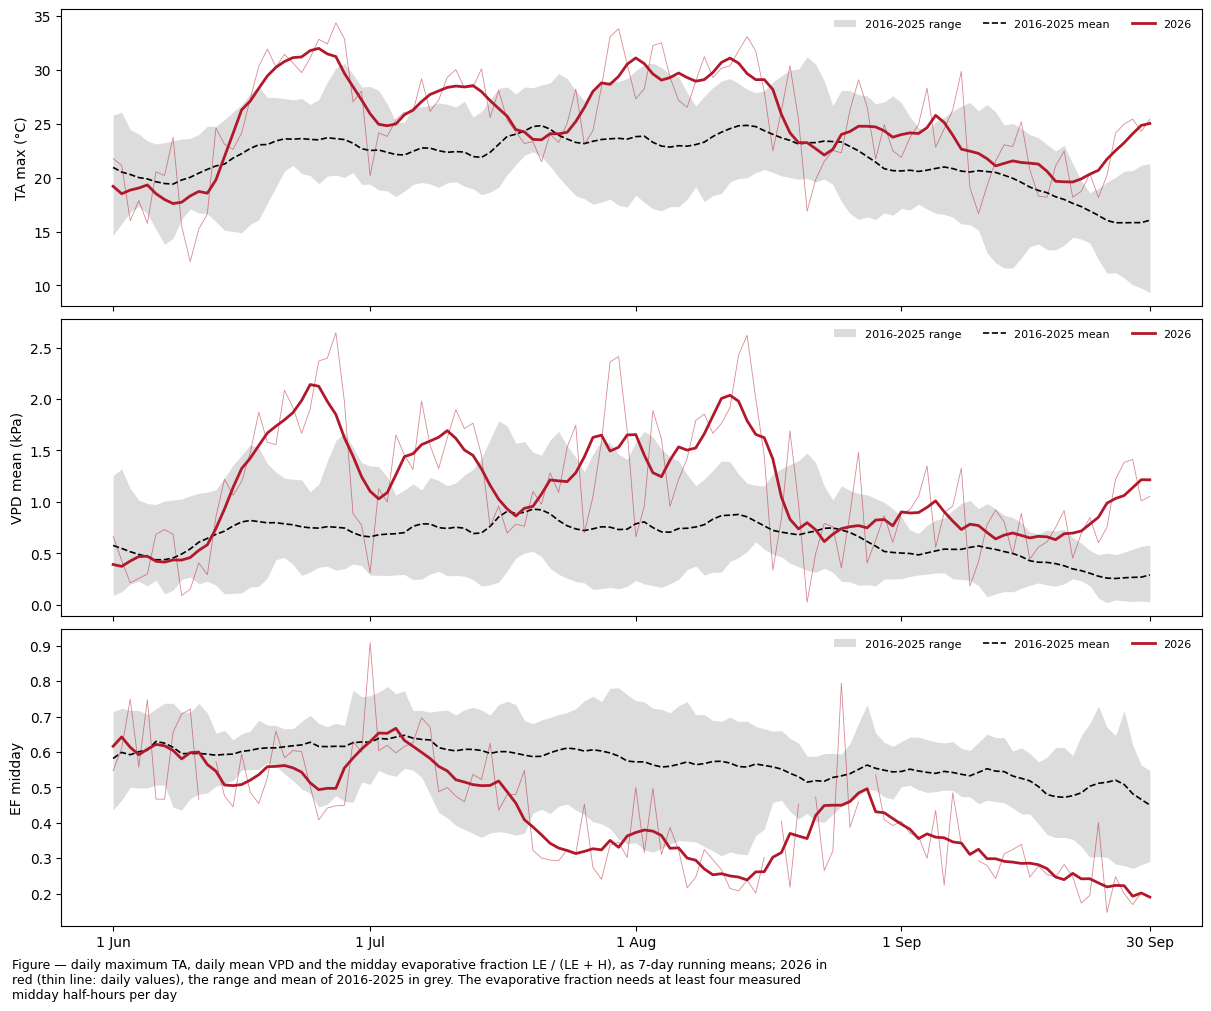

In [16]:
_d = pd.DataFrame({'TA max (°C)': s['TA'].resample('D').max(),
                   'VPD mean (kPa)': s['VPD'].resample('D').mean()}).dropna()
_e = _mid[[LE_GF, H_GF]].resample('D').agg(['sum', 'count'])
_d['EF midday'] = (_e[(LE_GF, 'sum')] / (_e[(LE_GF, 'sum')] + _e[(H_GF, 'sum')])).where(_e[(LE_GF, 'count')] >= 4)
_d = _d[_d.index.month.isin(MONTHS)]
_d['year'] = _d.index.year
_d['day'] = (_d.index - pd.DatetimeIndex(pd.to_datetime(_d['year'].astype(str) + '-06-01'))).days

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True, layout='constrained')
for ax, col in zip(axes, ['TA max (°C)', 'VPD mean (kPa)', 'EF midday']):
    wide = _d.pivot(index='day', columns='year', values=col).rolling(7, center=True, min_periods=3).mean()
    ref = wide[REF_YEARS]
    ax.fill_between(wide.index, ref.min(axis=1), ref.max(axis=1), color=C_REF, alpha=0.3, lw=0,
                    label=f'{REF_YEARS[0]}-{REF_YEARS[-1]} range')
    ax.plot(wide.index, ref.mean(axis=1), color='k', ls='--', lw=1.2, label=f'{REF_YEARS[0]}-{REF_YEARS[-1]} mean')
    ax.plot(_d.loc[_d['year'] == YEAR, 'day'], _d.loc[_d['year'] == YEAR, col], color=C_YEAR, lw=0.6, alpha=0.5)
    ax.plot(wide.index, wide[YEAR], color=C_YEAR, lw=2, label=f'{YEAR}')
    ax.set_ylabel(col)
    ax.legend(frameon=False, fontsize=8, ncols=3, loc='upper right')
axes[-1].set_xticks([0, 30, 61, 92, 121], ['1 Jun', '1 Jul', '1 Aug', '1 Sep', '30 Sep'])
figcap(fig, f"daily maximum TA, daily mean VPD and the midday evaporative fraction LE / (LE + H), as 7-day "
            f"running means; {YEAR} in red (thin line: daily values), the range and mean of "
            f"{REF_YEARS[0]}-{REF_YEARS[-1]} in grey. The evaporative fraction needs at least four measured "
            f"midday half-hours per day")
plt.show()

</br>

# 3. Uptake under heat: measured half-hours

This section uses measured `NEE` only (`CUT_50`, flags 0 and 1, no gap-filling) with the measured,
homogenised air temperature and measured radiation of the tower. Daytime is the `DAYTIME` flag of the
flux chain with `SW_IN` of at least 20 W m⁻²; `VPD` is used where it is measured. The question is
whether the forest took up less CO2 at the same light when it was hot or the air was dry, and
whether 2026 differs from the other years under the same conditions.

In [17]:
day = s[s[DAYTIME].eq(1) & s[NEE_MEAS].notna() & s[TA_MEAS].notna() & (s[SW_MEAS] >= SW_MIN)].copy()
day['VPD_meas'] = day['VPD'].where(day['VPD_FLAG'].eq(0))
day['group'] = np.where(day['year'] == YEAR, str(YEAR), f'{REF_YEARS[0]}-{REF_YEARS[-1]}')
day['SW class'] = pd.cut(day[SW_MEAS], SW_BINS, right=False)
day['TA class'] = pd.cut(day[TA_MEAS], TA_BINS, labels=TA_LABELS, right=False)
day['VPD class'] = pd.cut(day['VPD_meas'], VPD_BINS, labels=VPD_LABELS, right=False)
night = s[s[DAYTIME].eq(0) & s[NEE_MEAS].notna() & s[TA_MEAS].notna()].copy()
print(f"{len(day):,} measured daytime half-hours ({(day['year'] == YEAR).sum():,} in {YEAR}), "
      f"{len(night):,} measured night-time half-hours ({(night['year'] == YEAR).sum():,} in {YEAR})")

12,850 measured daytime half-hours (1,375 in 2026), 4,856 measured night-time half-hours (416 in 2026)


## 📋 Table: share of hot and dry half-hours among the measured daytime records

In [18]:
_t = pd.DataFrame({
    'measured daytime half-hours': day.groupby('year').size(),
    'share of all daytime (%)': day.groupby('year').size() / s[s[DAYTIME].eq(1) & (s[SW_MEAS] >= SW_MIN)].groupby('year').size() * 100,
    **{f'TA {l} (%)': day['TA class'].eq(l).groupby(day['year']).mean() * 100 for l in TA_LABELS[2:]},
    **{f'VPD {l} kPa (%)': day['VPD class'].eq(l).groupby(day['year']).mean() * 100 for l in VPD_LABELS[3:]},
})
display(styled(_t, caption=f"number of measured daytime NEE half-hours per year ({SEASON}), their share of all "
                           f"daytime half-hours, and the share of them in the hot and dry classes",
               fmt={c: "{:.0f}" if c.startswith('measured') else "{:.1f}" for c in _t.columns}, cmap=None))

Table — number of measured daytime NEE half-hours per year (Jun-Sep), their share of all daytime
half-hours, and the share of them in the hot and dry classes



,measured daytime half-hours,share of all daytime (%),TA 24-28 °C (%),TA ≥ 28 °C (%),VPD 1.5-2.0 kPa (%),VPD ≥ 2.0 kPa (%)
year,,,,,,
2016,1105,34.2,13.8,2.9,8.7,3.3
2017,1228,38.1,15.8,4.9,9.9,5.4
2018,1097,33.7,20.0,6.5,12.9,12.0
2019,1169,35.9,17.1,5.2,12.7,9.0
2020,1134,35.5,13.7,2.4,11.6,5.6
2021,998,31.2,9.1,0.4,5.6,0.7
2022,1383,43.0,18.6,6.2,17.4,11.6
2023,1174,36.1,10.8,3.6,14.3,4.7
2024,1050,33.4,13.4,1.4,5.1,1.0


## Light response by air-temperature class

### 📊 Plot: light response of measured NEE by TA class

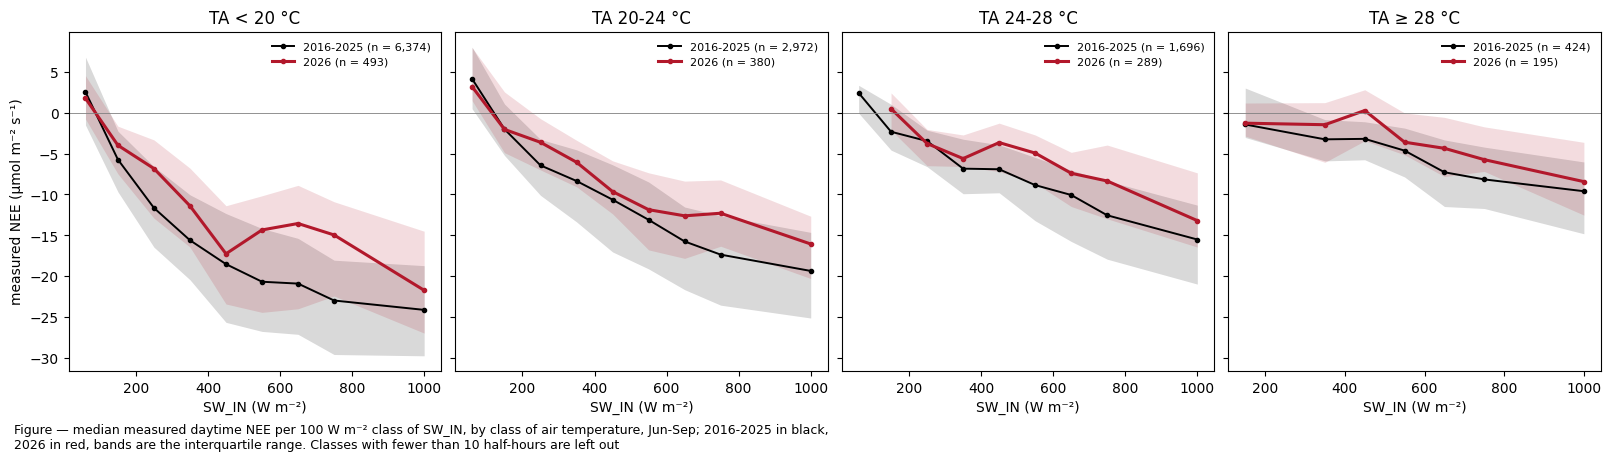

In [19]:
_mid_sw = {iv: iv.mid for iv in day['SW class'].cat.categories}
fig, axes = plt.subplots(1, len(TA_LABELS), figsize=(16, 4.5), sharey=True, layout='constrained')
for ax, lab in zip(axes, TA_LABELS):
    for grp, c, lw in ((f'{REF_YEARS[0]}-{REF_YEARS[-1]}', 'k', 1.4), (str(YEAR), C_YEAR, 2.2)):
        g = day[(day['TA class'] == lab) & (day['group'] == grp)].groupby('SW class', observed=True)[NEE_MEAS]
        st = g.agg(['median', 'size', lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
        st.columns = ['median', 'n', 'q25', 'q75']
        st = st[st['n'] >= MIN_N]
        x = [_mid_sw[i] for i in st.index]
        ax.fill_between(x, st['q25'], st['q75'], color=c, alpha=0.15, lw=0)
        ax.plot(x, st['median'], color=c, lw=lw, marker='o', ms=3, label=f"{grp} (n = {int(st['n'].sum()):,})")
    ax.axhline(0, color='0.5', lw=0.6)
    ax.set_title(f'TA {lab}')
    ax.set_xlabel('SW_IN (W m⁻²)')
    ax.legend(frameon=False, fontsize=8, loc='upper right')
axes[0].set_ylabel('measured NEE (µmol m⁻² s⁻¹)')
figcap(fig, f"median measured daytime NEE per 100 W m⁻² class of SW_IN, by class of air temperature, "
            f"{SEASON}; {REF_YEARS[0]}-{REF_YEARS[-1]} in black, {YEAR} in red, bands are the interquartile "
            f"range. Classes with fewer than {MIN_N} half-hours are left out")
plt.show()

### 📋 Table: high-light NEE by TA class

In [20]:
hi = day[day[SW_MEAS] >= SW_HIGH]
_m, _n = binned_mean(hi, NEE_MEAS, 'TA class', 'group')
_yr = hi[hi['year'].isin(REF_YEARS)].groupby(['TA class', 'year'], observed=True)[NEE_MEAS].agg(['mean', 'size'])
_yr = _yr[_yr['size'] >= MIN_N]['mean'].unstack()
_t = pd.DataFrame({f'{REF_YEARS[0]}-{REF_YEARS[-1]}': _m[f'{REF_YEARS[0]}-{REF_YEARS[-1]}'],
                   'lowest year mean': _yr.min(axis=1), 'highest year mean': _yr.max(axis=1),
                   str(YEAR): _m[str(YEAR)],
                   f'{YEAR} - reference': _m[str(YEAR)] - _m[f'{REF_YEARS[0]}-{REF_YEARS[-1]}'],
                   'n reference': _n[f'{REF_YEARS[0]}-{REF_YEARS[-1]}'], f'n {YEAR}': _n[str(YEAR)]})
_t.loc[_t[f'n {YEAR}'] < MIN_N, [str(YEAR), f'{YEAR} - reference']] = np.nan
ta_highlight = _t
display(styled(_t, caption=f"mean measured NEE at SW_IN of at least {SW_HIGH} W m⁻², by class of air "
                           f"temperature, in µmol m⁻² s⁻¹: the reference years together, the lowest and highest "
                           f"of their yearly means (years with at least {MIN_N} half-hours in the class), {YEAR}, "
                           f"and the difference (positive = less uptake in {YEAR})",
               fmt={**{c: "{:.2f}" for c in _t.columns}, 'n reference': "{:.0f}", f'n {YEAR}': "{:.0f}"},
               subset=[f'{YEAR} - reference']))

Table — mean measured NEE at SW_IN of at least 600 W m⁻², by class of air temperature, in µmol m⁻²
s⁻¹: the reference years together, the lowest and highest of their yearly means (years with at least
10 half-hours in the class), 2026, and the difference (positive = less uptake in 2026)



,2016-2025,lowest year mean,highest year mean,2026,2026 - reference,n reference,n 2026
TA class,,,,,,,
< 20 °C,-23.36,-25.77,-20.36,-19.12,4.24,1932,182
20-24 °C,-19.21,-23.14,-15.13,-15.19,4.01,1933,222
24-28 °C,-14.76,-18.34,-10.61,-11.46,3.30,1170,196
≥ 28 °C,-9.38,-14.97,-5.07,-6.57,2.81,302,119


## Light response by VPD class

### 📊 Plot: light response of measured NEE by VPD class

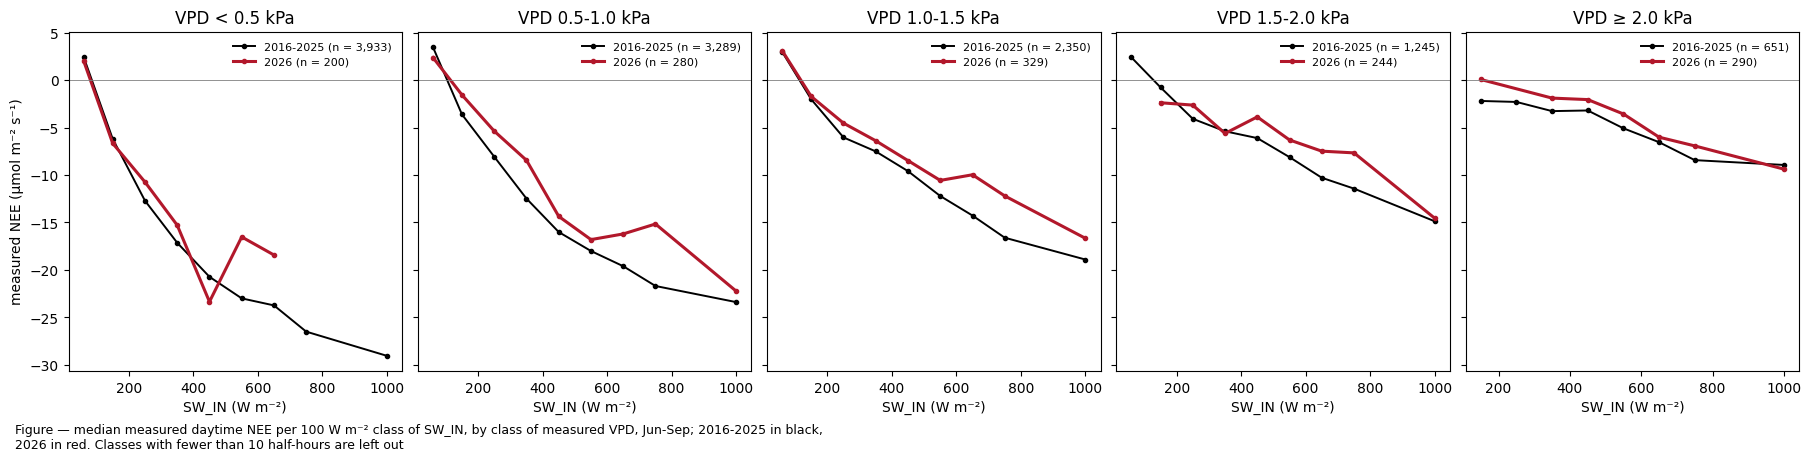

In [21]:
fig, axes = plt.subplots(1, len(VPD_LABELS), figsize=(18, 4.5), sharey=True, layout='constrained')
for ax, lab in zip(axes, VPD_LABELS):
    for grp, c, lw in ((f'{REF_YEARS[0]}-{REF_YEARS[-1]}', 'k', 1.4), (str(YEAR), C_YEAR, 2.2)):
        g = day[(day['VPD class'] == lab) & (day['group'] == grp)].groupby('SW class', observed=True)[NEE_MEAS]
        st = g.agg(['median', 'size'])
        st = st[st['size'] >= MIN_N]
        ax.plot([_mid_sw[i] for i in st.index], st['median'], color=c, lw=lw, marker='o', ms=3,
                label=f"{grp} (n = {int(st['size'].sum()):,})")
    ax.axhline(0, color='0.5', lw=0.6)
    ax.set_title(f'VPD {lab} kPa')
    ax.set_xlabel('SW_IN (W m⁻²)')
    ax.legend(frameon=False, fontsize=8, loc='upper right')
axes[0].set_ylabel('measured NEE (µmol m⁻² s⁻¹)')
figcap(fig, f"median measured daytime NEE per 100 W m⁻² class of SW_IN, by class of measured VPD, {SEASON}; "
            f"{REF_YEARS[0]}-{REF_YEARS[-1]} in black, {YEAR} in red. Classes with fewer than {MIN_N} "
            f"half-hours are left out")
plt.show()

### 📋 Table: high-light NEE by VPD class

In [22]:
_m, _n = binned_mean(hi.dropna(subset=['VPD class']), NEE_MEAS, 'VPD class', 'group')
_t = pd.DataFrame({f'{REF_YEARS[0]}-{REF_YEARS[-1]}': _m[f'{REF_YEARS[0]}-{REF_YEARS[-1]}'], str(YEAR): _m[str(YEAR)],
                   f'{YEAR} - reference': _m[str(YEAR)] - _m[f'{REF_YEARS[0]}-{REF_YEARS[-1]}'],
                   'n reference': _n[f'{REF_YEARS[0]}-{REF_YEARS[-1]}'], f'n {YEAR}': _n[str(YEAR)]})
_t.loc[_t[f'n {YEAR}'] < MIN_N, [str(YEAR), f'{YEAR} - reference']] = np.nan
_t.loc[_t['n reference'] < MIN_N, [f'{REF_YEARS[0]}-{REF_YEARS[-1]}', f'{YEAR} - reference']] = np.nan
vpd_highlight = _t
display(styled(_t, caption=f"mean measured NEE at SW_IN of at least {SW_HIGH} W m⁻², by class of measured VPD "
                           f"(kPa), in µmol m⁻² s⁻¹, and the difference of {YEAR} to the reference years "
                           f"(positive = less uptake in {YEAR}). Classes with fewer than {MIN_N} half-hours "
                           f"are left out",
               fmt={**{c: "{:.2f}" for c in _t.columns}, 'n reference': "{:.0f}", f'n {YEAR}': "{:.0f}"},
               subset=[f'{YEAR} - reference']))

Table — mean measured NEE at SW_IN of at least 600 W m⁻², by class of measured VPD (kPa), in µmol
m⁻² s⁻¹, and the difference of 2026 to the reference years (positive = less uptake in 2026). Classes
with fewer than 10 half-hours are left out



,2016-2025,2026,2026 - reference,n reference,n 2026
VPD class,,,,,
< 0.5,-25.84,-23.27,2.57,660,23
0.5-1.0,-22.62,-19.89,2.73,1738,156
1.0-1.5,-18.35,-14.38,3.97,1623,190
1.5-2.0,-14.08,-12.46,1.61,873,158
≥ 2.0,-8.87,-8.04,0.83,443,192


## Weather effect and remaining difference

Each measured daytime half-hour of 2026 is given the mean measured `NEE` of the reference years in
the same month, the same 100 W m⁻² class of `SW_IN` and the same 2 K class of `TA` (or 0.25 kPa
class of `VPD`), where at least 10 reference half-hours fall in that cell. Comparing three means per
month separates two parts of the difference between 2026 and the reference years:

- **effect of the conditions**: the expected `NEE` of the 2026 conditions minus the mean of the
  reference half-hours of the month. It is what the reference years would have done under the light,
  temperature or `VPD` of 2026.
- **remaining difference**: the measured `NEE` of 2026 minus its expected value. It is what the
  conditions of the half-hour do not explain: lagged effects of heat and drought, a lower leaf area,
  earlier senescence, or soil water that the half-hourly conditions do not show.

The same is done for the night-time half-hours with the month and the 1 K class of `TA`: it shows
whether respiration at the same temperature differed in 2026.

In [23]:
def lookup_residual(frame, keys, value=NEE_MEAS):
    """Expected `value` of each YEAR half-hour from the reference half-hours in the same `keys` cell."""
    ref = frame[frame['year'].isin(REF_YEARS)]
    cell = ref.groupby(keys, observed=True)[value].agg(['mean', 'size'])
    cell = cell[cell['size'] >= MIN_N]['mean'].rename('expected')
    yr = frame[frame['year'] == YEAR].join(cell, on=keys)
    rows = {}
    for m, g in yr.groupby('month'):
        ok = g['expected'].notna()
        rows[calendar.month_abbr[m]] = {
            'reference': ref.loc[ref['month'] == m, value].mean(),
            f'expected for {YEAR}': g.loc[ok, 'expected'].mean(),
            f'measured {YEAR}': g.loc[ok, value].mean(),
            'n': ok.sum(), 'covered (%)': ok.mean() * 100}
    ok = yr['expected'].notna()
    rows[SEASON] = {'reference': ref[value].mean(), f'expected for {YEAR}': yr.loc[ok, 'expected'].mean(),
                    f'measured {YEAR}': yr.loc[ok, value].mean(), 'n': ok.sum(), 'covered (%)': ok.mean() * 100}
    out = pd.DataFrame(rows).T
    out['effect of conditions'] = out[f'expected for {YEAR}'] - out['reference']
    out['remaining difference'] = out[f'measured {YEAR}'] - out[f'expected for {YEAR}']
    return out[['reference', f'expected for {YEAR}', f'measured {YEAR}', 'effect of conditions',
                'remaining difference', 'n', 'covered (%)']]


day['TA 2K'] = np.floor(day[TA_MEAS] / 2) * 2
day['VPD 0.25'] = np.floor(day['VPD_meas'] / 0.25) * 0.25
night['TA 1K'] = np.floor(night[TA_MEAS])
night['TA 2K'] = np.floor(night[TA_MEAS] / 2) * 2
res_ta = lookup_residual(day, ['month', 'SW class', 'TA 2K'])
res_vpd = lookup_residual(day.dropna(subset=['VPD 0.25']), ['month', 'SW class', 'VPD 0.25'])
res_night = lookup_residual(night, ['month', 'TA 1K'])
_fmt = {'n': "{:.0f}", 'covered (%)': "{:.0f}"}
_sub = ['effect of conditions', 'remaining difference']

### 📋 Table: daytime NEE of 2026 against the reference at the same light and temperature

In [24]:
display(styled(res_ta, caption=f"mean measured daytime NEE in µmol m⁻² s⁻¹ per month: the reference years, the "
                               f"value expected for the {YEAR} half-hours from the reference years at the same "
                               f"month, SW_IN class and 2 K TA class, and the measured {YEAR} value. Positive "
                               f"numbers mean less uptake. n is the number of {YEAR} half-hours with a "
                               f"reference cell, covered their share of all", fmt=_fmt, subset=_sub))

Table — mean measured daytime NEE in µmol m⁻² s⁻¹ per month: the reference years, the value expected
for the 2026 half-hours from the reference years at the same month, SW_IN class and 2 K TA class,
and the measured 2026 value. Positive numbers mean less uptake. n is the number of 2026 half-hours
with a reference cell, covered their share of all



,reference,expected for 2026,measured 2026,effect of conditions,remaining difference,n,covered (%)
Jun,-15.67,-16.17,-16.59,-0.50,-0.41,300,87
Jul,-14.11,-13.82,-12.30,0.29,1.51,392,93
Aug,-12.58,-11.76,-6.70,0.82,5.06,308,86
Sep,-12.59,-13.65,-7.21,-1.06,6.44,220,89
Jun-Sep,-13.91,-13.85,-11.02,0.07,2.82,1220,89


### 📋 Table: daytime NEE of 2026 against the reference at the same light and VPD

In [25]:
display(styled(res_vpd, caption=f"as the table above, with 0.25 kPa classes of measured VPD instead of TA",
               fmt=_fmt, subset=_sub))

Table — as the table above, with 0.25 kPa classes of measured VPD instead of TA



,reference,expected for 2026,measured 2026,effect of conditions,remaining difference,n,covered (%)
Jun,-15.67,-15.93,-17.83,-0.26,-1.90,278,80
Jul,-14.11,-13.22,-13.23,0.89,-0.02,343,81
Aug,-12.58,-12.13,-7.48,0.45,4.65,276,77
Sep,-12.59,-13.08,-7.60,-0.49,5.47,199,80
Jun-Sep,-13.91,-13.61,-11.93,0.31,1.68,1096,80


### 📋 Table: night-time NEE of 2026 against the reference at the same temperature

In [26]:
display(styled(res_night, caption=f"mean measured night-time NEE (respiration) in µmol m⁻² s⁻¹ per month: the "
                                  f"reference years, the value expected for the {YEAR} half-hours from the "
                                  f"reference years at the same month and 1 K TA class, and the measured {YEAR} "
                                  f"value. A negative remaining difference means lower respiration than at the "
                                  f"same temperature in the reference years", fmt=_fmt, subset=_sub))

Table — mean measured night-time NEE (respiration) in µmol m⁻² s⁻¹ per month: the reference years,
the value expected for the 2026 half-hours from the reference years at the same month and 1 K TA
class, and the measured 2026 value. A negative remaining difference means lower respiration than at
the same temperature in the reference years



,reference,expected for 2026,measured 2026,effect of conditions,remaining difference,n,covered (%)
Jun,6.99,6.51,6.49,-0.48,-0.02,62,86
Jul,6.62,6.52,5.11,-0.10,-1.41,132,96
Aug,6.70,6.54,4.64,-0.16,-1.90,130,94
Sep,5.73,5.84,5.25,0.11,-0.59,66,97
Jun-Sep,6.46,6.41,5.20,-0.05,-1.22,390,94


### 📊 Plot: effect of the conditions and remaining difference per month

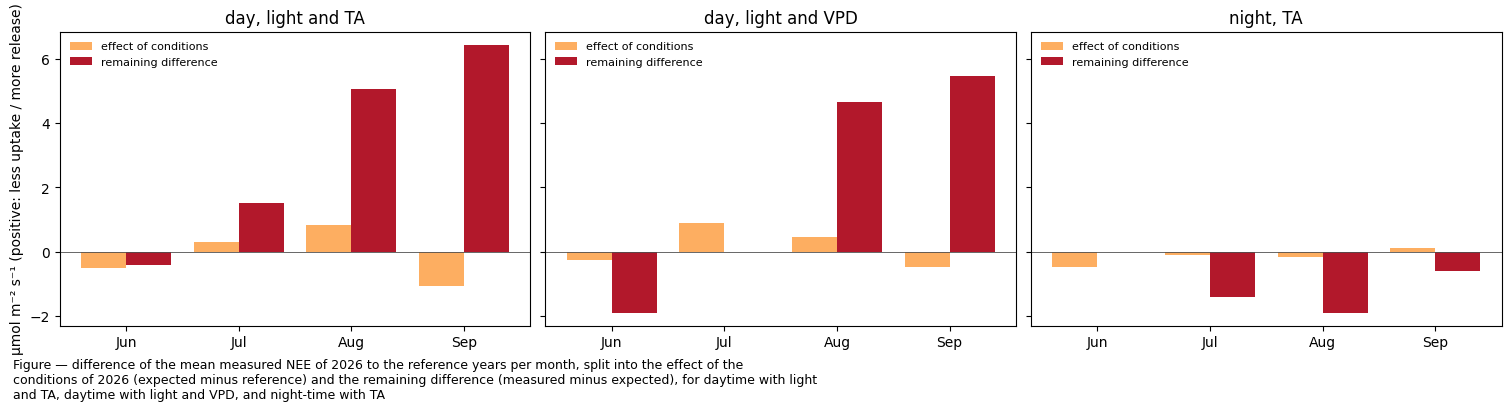

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, layout='constrained')
for ax, (name, r) in zip(axes, [('day, light and TA', res_ta), ('day, light and VPD', res_vpd),
                                ('night, TA', res_night)]):
    r = r.drop(index=SEASON)
    x = np.arange(len(r))
    ax.bar(x - 0.2, r['effect of conditions'], 0.4, color='#fdae61', label='effect of conditions')
    ax.bar(x + 0.2, r['remaining difference'], 0.4, color=C_YEAR, label='remaining difference')
    ax.axhline(0, color='0.3', lw=0.6)
    ax.set_xticks(x, r.index)
    ax.set_title(name)
    ax.legend(frameon=False, fontsize=8, loc='upper left')
axes[0].set_ylabel('µmol m⁻² s⁻¹ (positive: less uptake / more release)')
figcap(fig, f"difference of the mean measured NEE of {YEAR} to the reference years per month, split into the "
            f"effect of the conditions of {YEAR} (expected minus reference) and the remaining difference "
            f"(measured minus expected), for daytime with light and TA, daytime with light and VPD, and "
            f"night-time with TA")
plt.show()

### 📊 Plot: night-time NEE against air temperature

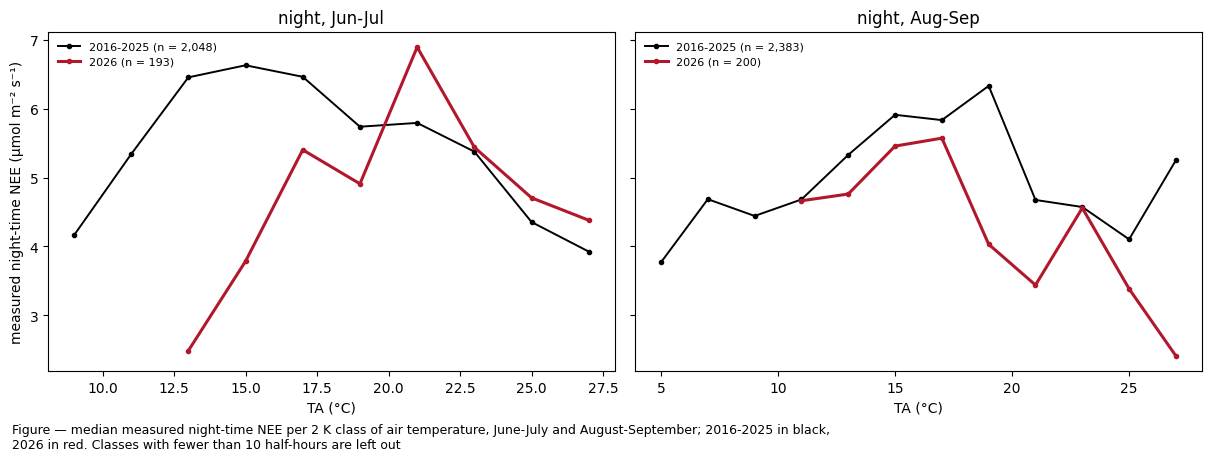

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, layout='constrained')
for ax, months in zip(axes, ([6, 7], [8, 9])):
    sub = night[night['month'].isin(months)]
    for grp, c, lw in ((REF_YEARS, 'k', 1.4), ([YEAR], C_YEAR, 2.2)):
        g = sub[sub['year'].isin(grp)].groupby('TA 2K')[NEE_MEAS].agg(['median', 'size'])
        g = g[g['size'] >= MIN_N]
        lab = f'{REF_YEARS[0]}-{REF_YEARS[-1]}' if len(grp) > 1 else str(YEAR)
        ax.plot(g.index + 1, g['median'], color=c, lw=lw, marker='o', ms=3, label=f"{lab} (n = {int(g['size'].sum()):,})")
    ax.set_title(f"night, {calendar.month_abbr[months[0]]}-{calendar.month_abbr[months[1]]}")
    ax.set_xlabel('TA (°C)')
    ax.legend(frameon=False, fontsize=8, loc='upper left')
axes[0].set_ylabel('measured night-time NEE (µmol m⁻² s⁻¹)')
figcap(fig, f"median measured night-time NEE per 2 K class of air temperature, June-July and August-September; "
            f"{REF_YEARS[0]}-{REF_YEARS[-1]} in black, {YEAR} in red. Classes with fewer than {MIN_N} "
            f"half-hours are left out")
plt.show()

</br>

# 4. Lower GPP or higher RECO: months and weeks

The difference of `NEE` from the reference mean splits exactly into the differences of `RECO` and
`GPP`: Δ`NEE` = Δ`RECO` − Δ`GPP`. Both partitioning methods are shown. The nighttime method
extrapolates the temperature response of night-time respiration to the day, so on hot days its
daytime `RECO`, and with it `GPP`, depends on that extrapolation; the daytime method fits respiration
and photosynthesis to the daytime fluxes together. The nighttime method derives `GPP` as `RECO`
minus `NEE`, so its two parts add up to the `NEE` anomaly exactly. In the daytime method `GPP` and
`RECO` are both model outputs; over June-September of the reference years their difference is
about 120 gC m⁻² less negative than the gap-filled `NEE`, so it is used here for the direction of
the changes, not to split the `NEE` anomaly.

In [29]:
_cols = {'NEE': NEE_GF['CUT_50']} | PART
monthly = (s[list(_cols.values())] * GC).groupby([s['year'], s['month']]).sum()
monthly.columns = list(_cols)
_ref = monthly.loc[REF_YEARS].groupby(level='month')
_yr = monthly.loc[YEAR]

## 📋 Table: monthly sums of 2026 against the reference mean

In [30]:
_rows = {}
for m in MONTHS:
    r = {}
    for v in _cols:
        r[f'{v} {YEAR}'] = _yr.loc[m, v]
        r[f'{v} ref mean'] = _ref.mean().loc[m, v]
        r[f'{v} ref min-max'] = f"{_ref.min().loc[m, v]:.0f} to {_ref.max().loc[m, v]:.0f}"
    _rows[calendar.month_abbr[m]] = r
_rows[SEASON] = {**{f'{v} {YEAR}': _yr[v].sum() for v in _cols},
                 **{f'{v} ref mean': monthly.loc[REF_YEARS, v].groupby(level='year').sum().mean() for v in _cols},
                 **{f'{v} ref min-max': f"{monthly.loc[REF_YEARS, v].groupby(level='year').sum().min():.0f} to "
                                       f"{monthly.loc[REF_YEARS, v].groupby(level='year').sum().max():.0f}" for v in _cols}}
_t = pd.DataFrame(_rows).T.infer_objects()
display(styled(_t, caption=f"monthly sums of NEE (CUT_50), GPP and RECO (NT and DT partitioning) of {YEAR}, the "
                           f"mean and the range of the monthly sums of {REF_YEARS[0]}-{REF_YEARS[-1]}, in gC m⁻²",
               fmt="{:.0f}", cmap=None))

Table — monthly sums of NEE (CUT_50), GPP and RECO (NT and DT partitioning) of 2026, the mean and
the range of the monthly sums of 2016-2025, in gC m⁻²



,NEE 2026,NEE ref mean,NEE ref min-max,GPP_NT 2026,GPP_NT ref mean,GPP_NT ref min-max,RECO_NT 2026,RECO_NT ref mean,RECO_NT ref min-max,GPP_DT 2026,GPP_DT ref mean,GPP_DT ref min-max,RECO_DT 2026,RECO_DT ref mean,RECO_DT ref min-max
Jun,-125,-134,-159 to -107,335,361,326 to 382,210,227,201 to 258,329,343,259 to 425,210,245,189 to 324
Jul,-104,-114,-161 to -70,281,333,276 to 427,176,219,169 to 313,296,367,278 to 426,196,290,140 to 367
Aug,-3,-66,-110 to -25,152,283,205 to 348,149,217,170 to 278,196,333,237 to 445,204,297,185 to 455
Sep,5,-46,-88 to -25,165,236,201 to 306,170,189,143 to 255,160,253,195 to 345,137,226,137 to 438
Jun-Sep,-228,-361,-513 to -240,933,1213,1025 to 1341,705,852,703 to 1000,981,1295,1033 to 1457,747,1058,822 to 1409


## 📋 Table: monthly anomalies of NEE, GPP and RECO in 2026

In [31]:
_anom = (_yr - _ref.mean())
_anom.index = [calendar.month_abbr[m] for m in _anom.index]
_anom.loc[SEASON] = _anom.sum()
_anom['RECO_NT - GPP_NT'] = _anom['RECO_NT'] - _anom['GPP_NT']
_anom['RECO_DT - GPP_DT'] = _anom['RECO_DT'] - _anom['GPP_DT']
monthly_anom = _anom
display(styled(_anom, caption=f"difference of the monthly sums of {YEAR} to the mean of {REF_YEARS[0]}-"
                              f"{REF_YEARS[-1]}, in gC m⁻². Positive NEE is less net uptake. The last two "
                              f"columns rebuild the NEE difference from the partitioned fluxes. The nighttime "
                              f"method derives GPP as RECO minus NEE and rebuilds it exactly; in the daytime "
                              f"method GPP and RECO are both model outputs, and their difference does not "
                              f"follow the gap-filled NEE",
               fmt="{:+.0f}"))

Table — difference of the monthly sums of 2026 to the mean of 2016-2025, in gC m⁻². Positive NEE is
less net uptake. The last two columns rebuild the NEE difference from the partitioned fluxes. The
nighttime method derives GPP as RECO minus NEE and rebuilds it exactly; in the daytime method GPP
and RECO are both model outputs, and their difference does not follow the gap-filled NEE



,NEE,GPP_NT,RECO_NT,GPP_DT,RECO_DT,RECO_NT - GPP_NT,RECO_DT - GPP_DT
Jun,+8,-25,-17,-14,-35,+8,-21
Jul,+10,-53,-43,-70,-94,+10,-23
Aug,+63,-131,-68,-137,-94,+63,+43
Sep,+52,-71,-19,-93,-89,+52,+4
Jun-Sep,+133,-280,-147,-314,-312,+133,+2


## 📊 Plot: weekly anomalies of NEE, GPP and RECO in 2026

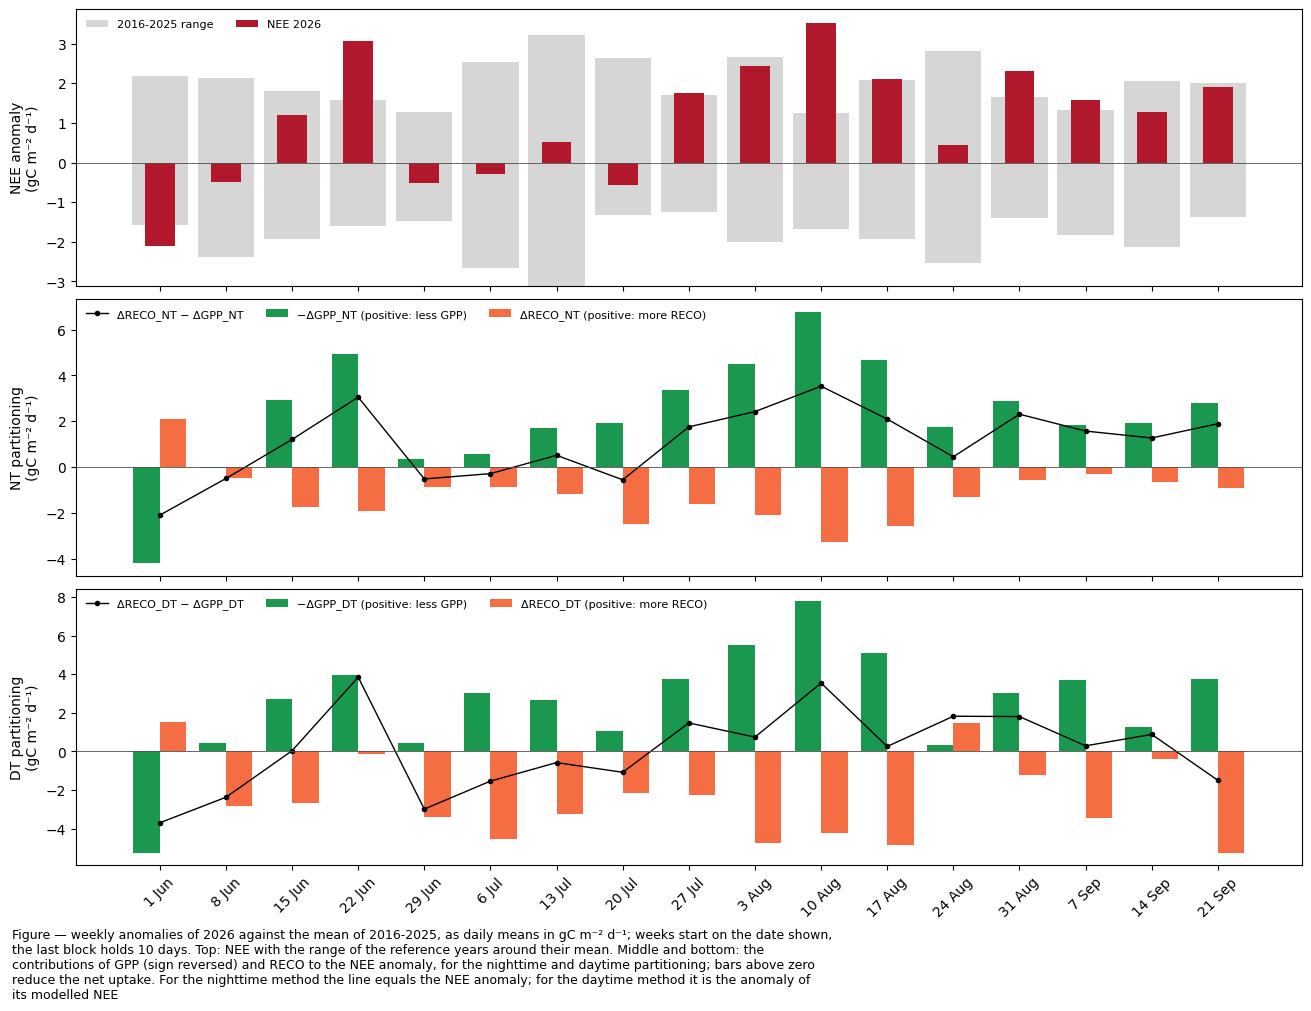

In [32]:
s['week'] = week_of_season(s.index)
_wcols = {'NEE': NEE_GF['CUT_50'], 'GPP_NT': PART['GPP_NT'], 'RECO_NT': PART['RECO_NT'],
          'GPP_DT': PART['GPP_DT'], 'RECO_DT': PART['RECO_DT']}
weekly = (s[list(_wcols.values())] * GC).groupby([s['year'], s['week']]).sum()
weekly.columns = list(_wcols)
# Weekly sums divided by the number of days, so the last, 10-day block compares with the others.
_days = s.groupby([s['year'], s['week']]).size() / 48
weekly = weekly.div(_days, axis=0)
_wref = weekly.loc[REF_YEARS].groupby(level='week')
weekly_anom = weekly.loc[YEAR] - _wref.mean()
_start = pd.Timestamp(f'{YEAR}-06-01') + pd.to_timedelta(weekly_anom.index * 7, unit='D')
_lab = [f"{d.day} {calendar.month_abbr[d.month]}" for d in _start]

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True, layout='constrained')
x = np.arange(len(weekly_anom))
ax = axes[0]
_lo, _hi = _wref.min()['NEE'] - _wref.mean()['NEE'], _wref.max()['NEE'] - _wref.mean()['NEE']
ax.bar(x, _hi - _lo, 0.85, bottom=_lo, color=C_REF, alpha=0.35, label=f'{REF_YEARS[0]}-{REF_YEARS[-1]} range')
ax.bar(x, weekly_anom['NEE'], 0.45, color=C_YEAR, label=f'NEE {YEAR}')
ax.set_ylabel('NEE anomaly\n(gC m⁻² d⁻¹)')
for ax, (g, r) in zip(axes[1:], [('GPP_NT', 'RECO_NT'), ('GPP_DT', 'RECO_DT')]):
    ax.bar(x - 0.2, -weekly_anom[g], 0.4, color='#1a9850', label=f'−Δ{g} (positive: less GPP)')
    ax.bar(x + 0.2, weekly_anom[r], 0.4, color='#f46d43', label=f'Δ{r} (positive: more RECO)')
    ax.plot(x, weekly_anom[r] - weekly_anom[g], color='k', marker='o', ms=3, lw=1, label=f"Δ{r} − Δ{g}")
    ax.set_ylabel(f"{g.split('_')[1]} partitioning\n(gC m⁻² d⁻¹)")
for ax in axes:
    ax.axhline(0, color='0.3', lw=0.6)
    ax.legend(frameon=False, fontsize=8, ncols=3, loc='upper left')
axes[-1].set_xticks(x, _lab, rotation=45)
figcap(fig, f"weekly anomalies of {YEAR} against the mean of {REF_YEARS[0]}-{REF_YEARS[-1]}, as daily means "
            f"in gC m⁻² d⁻¹; weeks start on the date shown, the last block holds 10 days. Top: NEE with the "
            f"range of the reference years around their mean. Middle and bottom: the contributions of GPP "
            f"(sign reversed) and RECO to the NEE anomaly, for the nighttime and daytime partitioning; "
            f"bars above zero reduce the net uptake. For the nighttime method the line equals the NEE "
            f"anomaly; for the daytime method it is the anomaly of its modelled NEE")
plt.show()

## 📋 Table: weekly anomalies of NEE, GPP and RECO in 2026

In [33]:
_t = weekly_anom.copy()
_t.index = _lab
_t.index.name = 'week from'
display(styled(_t, caption=f"weekly anomalies of {YEAR} against the mean of {REF_YEARS[0]}-{REF_YEARS[-1]}, "
                           f"daily means in gC m⁻² d⁻¹; positive NEE and RECO, negative GPP reduce the net "
                           f"uptake", fmt="{:+.2f}"))

Table — weekly anomalies of 2026 against the mean of 2016-2025, daily means in gC m⁻² d⁻¹; positive
NEE and RECO, negative GPP reduce the net uptake



,NEE,GPP_NT,RECO_NT,GPP_DT,RECO_DT
week from,,,,,
1 Jun,-2.10,+4.19,+2.09,+5.24,+1.55
8 Jun,-0.50,+0.04,-0.46,-0.44,-2.82
15 Jun,+1.21,-2.93,-1.72,-2.71,-2.67
22 Jun,+3.05,-4.95,-1.89,-3.97,-0.13
29 Jun,-0.52,-0.35,-0.86,-0.42,-3.40
6 Jul,-0.28,-0.56,-0.85,-3.02,-4.56
13 Jul,+0.52,-1.70,-1.19,-2.65,-3.23
20 Jul,-0.55,-1.93,-2.48,-1.07,-2.15
27 Jul,+1.76,-3.35,-1.59,-3.73,-2.26


</br>

# Conclusion

**Did the hot summer of 2026 reduce net CO2 uptake?** Yes. From June to September 2026, CH-LAE
took up 228 gC m⁻², 37 % less than the 2016-2025 mean and the least of the LI-7200 record in every
USTAR scenario. The difference to 2022, the next weakest season and also a hot and dry summer, is
small (12 gC m⁻²), so 2026 extends the range of the record rather than lying far outside it.

**How the reduction came about.** It was a reduction of gross uptake, not an increase of
respiration. `GPP` was the lowest of the record with both partitioning methods; `RECO` was also
lower than in most years, and lower than the reference years at the same night-time temperature,
which offset about half of the `GPP` deficit. The reduction is concentrated in August and
September; June and July were close to the mean despite the heat spell of late June.

**The role of heat.** Uptake at high light decreases with air temperature and `VPD` in every year,
and 2026 had about four times as many hot half-hours as the reference years. Compared at the same
month, light and temperature or `VPD`, however, these conditions account for only a small part of
the deficit. In August and September uptake was lower at all temperatures, including below 20 °C,
and the evaporative fraction kept falling after the heat had passed. This points to a cumulative
effect of the hot and dry season, such as depleted soil water, stomatal closure or early
senescence, rather than to the direct effect of the hot half-hours. Precipitation and soil water
content of 2026 are needed to separate these causes.

**Open**

- Precipitation and soil water content of 2026, once the meteo products are extended: they decide
  whether the late-season reduction is a soil drought effect.
- October to December 2026: whether uptake recovers after September, and how the annual sum
  compares.
- Leaf area or phenology observations (for example from cameras or remote sensing) to test for
  early senescence in August and September 2026.

</br>

# End of notebook

In [34]:
_dt = datetime.now() - NOTEBOOK_START
print(f"Finished {datetime.now():%Y-%m-%d %H:%M:%S}; runtime {_dt.total_seconds() / 60:.1f} min")

Finished 2026-11-19 17:07:49; runtime 0.1 min
